# Kazakhstan internal migration — Version 2
We compare 5 original predictors with 10 predictors including education, healthcare and housing. Each row is one region in one year. **2024–2025 were already examined in Version 1; they are not a fresh untouched test.** Run cells from top to bottom.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util
repository = "https://github.com/aluasagyndyk2/kazakhstan-internal-migration-ml.git"
project = Path.cwd()
if not (project / "build_core_dataset.py").is_file():
    project = project / "kazakhstan-internal-migration-ml-v2"
    if not project.exists():
        subprocess.run(["git", "clone", repository, str(project)], check=True)
    os.chdir(project)
sys.path.insert(0, str(Path.cwd()))
required = {"pandas":"pandas", "numpy":"numpy", "sklearn":"scikit-learn", "matplotlib":"matplotlib", "openpyxl":"openpyxl", "xlrd":"xlrd", "shap":"shap"}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
assert Path("build_core_dataset.py").is_file(), "Open the Version 2 project, not the old Version 1 folder."
print("Version 2 project is ready.")

Version 2 project is ready.


## 1. Real data sources
Twelve unchanged official BNS workbooks are included. Education uses the start year of the academic year; all predictors come from the preceding year.

In [2]:
import pandas as pd
import json
from IPython.display import display, Image
from build_dataset import build_dataset, FEATURES, CORE_FEATURES, GROUPS
display(pd.read_json("source_manifest.json")[["id", "title_en", "url", "updated", "accessed"]])

,id,title_en,url,updated,accessed
0,population,Average annual population,https://stat.gov.kz/api/iblock/element/6576/fi...,27.03.2026,2026-10-24
1,migration_in,Internal migration arrivals,https://stat.gov.kz/api/iblock/element/449808/...,25.09.2026,2026-10-24
2,migration_out,Internal migration departures,https://stat.gov.kz/api/iblock/element/449809/...,25.09.2026,2026-10-24
3,migration_net,Net internal migration,https://stat.gov.kz/api/iblock/element/449807/...,25.09.2026,2026-10-24
4,unemployment,Unemployment rate,https://stat.gov.kz/api/iblock/element/102790/...,19.06.2026,2026-10-24
5,income,Per capita nominal income,https://stat.gov.kz/api/iblock/element/19298/f...,02.10.2026,2026-10-24
6,wages,Average monthly wages,https://stat.gov.kz/api/iblock/element/5676/fi...,10.09.2026,2026-10-24
7,schools,Number of general education schools,https://stat.gov.kz/api/iblock/element/3759/fi...,13.08.2026,2026-10-24
8,students,Higher education students,https://stat.gov.kz/api/iblock/element/3736/fi...,21.01.2026,2026-10-24
9,beds,Hospital beds,https://stat.gov.kz/api/iblock/element/3692/fi...,29.09.2026,2026-10-24


## 2. Prepare the dataset
The two feature sets use the same observations. A model predicting a 2024 outcome uses predictor values from 2023.

In [3]:
dataset = build_dataset()
print("Rows:", len(dataset), "| Core features:", len(CORE_FEATURES), "| Extended features:", len(FEATURES))
display(dataset.groupby("year").agg(observations=("target", "size"), positive=("target", "sum")))
display(dataset[["region", "year", "feature_year", *FEATURES, "target"]].head(5).round(3))

VERSION 2 MATCHED SAMPLE
{
  "version": 2,
  "raw_rows": 240,
  "core_eligible_rows": 164,
  "matched_rows": 164,
  "missing_extended_rows": 0,
  "positive": 40,
  "negative": 124,
  "development_rows": 124,
  "previously_seen_final_slice_rows": 40,
  "features": [
    "income_ratio_lag1",
    "wage_ratio_lag1",
    "unemployment_lag1",
    "urban_share_lag1",
    "log_population_lag1",
    "schools_per_10000_lag1",
    "students_per_10000_lag1",
    "doctors_per_10000_lag1",
    "beds_per_10000_lag1",
    "housing_sqm_per_person_lag1"
  ],
  "feature_groups": {
    "Core socioeconomic": [
      "income_ratio_lag1",
      "wage_ratio_lag1",
      "unemployment_lag1",
      "urban_share_lag1",
      "log_population_lag1"
    ],
    "Education": [
      "schools_per_10000_lag1",
      "students_per_10000_lag1"
    ],
    "Healthcare": [
      "doctors_per_10000_lag1",
      "beds_per_10000_lag1"
    ],
    "Housing": [
      "housing_sqm_per_person_lag1"
    ]
  },
  "feature_missing": 0

,observations,positive
year,,
2015,12,6
2016,12,2
2017,12,3
2018,12,2
2019,14,4
2020,14,4
2021,14,4
2022,14,3
2023,20,3


,region,year,feature_year,income_ratio_lag1,wage_ratio_lag1,unemployment_lag1,urban_share_lag1,log_population_lag1,schools_per_10000_lag1,students_per_10000_lag1,doctors_per_10000_lag1,beds_per_10000_lag1,housing_sqm_per_person_lag1,target
0,Akmola,2015,2014,0.847,0.706,4.9,0.482,13.507,8.342,140.025,30.308,69.747,0.365,1
1,Aktobe,2015,2014,0.964,0.878,4.9,0.681,13.611,5.434,255.469,45.414,55.387,0.584,0
2,Atyrau,2015,2014,2.003,1.832,5.0,0.540,13.261,3.463,183.634,29.480,57.725,0.908,0
3,West Kazakhstan,2015,2014,0.996,0.894,5.0,0.495,13.349,6.556,452.542,30.787,68.737,0.410,1
4,Zhambyl,2015,2014,0.639,0.677,4.9,0.403,13.902,4.256,179.607,27.418,55.909,0.237,0


## 3. Models and chronological checks
Settings are fixed, seed = 42. Train on earlier years and check the next year, for 2019 through 2025. Family selection uses 2019–2023 only. The 2025 model includes 2024 outcomes in training.

In [4]:
import inspect
from model_utils_v1 import models
print(inspect.getsource(models))
from run_analysis import temporal_splits
display(pd.DataFrame([{"evaluate_year": year, "train_rows": len(train), "check_rows": len(valid), "last_train_year": train.year.max()} for year, train, valid in temporal_splits(dataset, range(2019, 2026))]))

def models():
    choices={
        'Majority dummy':DummyClassifier(strategy='most_frequent'),
        'Logistic Regression':LogisticRegression(C=1.0,max_iter=2000,random_state=42),
        'Decision Tree':DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=42),
        'Random Forest':RandomForestClassifier(n_estimators=300,max_depth=4,min_samples_leaf=3,max_features='sqrt',random_state=42,n_jobs=1),
        'Gradient Boosting':GradientBoostingClassifier(n_estimators=100,learning_rate=0.05,max_depth=2,min_samples_leaf=5,random_state=42)
    }
    result={}
    for name,model in choices.items():
        steps=[('impute',SimpleImputer(strategy='median'))]
        if name=='Logistic Regression': steps.append(('scale',StandardScaler()))
        result[name]=Pipeline(steps+[('model',model)])
    return result



,evaluate_year,train_rows,check_rows,last_train_year
0,2019,48,14,2018
1,2020,62,14,2019
2,2021,76,14,2020
3,2022,90,14,2021
4,2023,104,20,2022
5,2024,124,20,2023
6,2025,144,20,2024


## 4. Run the comparison and explanation
This cell runs all four models and both reference methods, then computes validation importance and real SHAP explanations. It can take several minutes.

In [5]:
from run_analysis import main
main()

Frozen V2 protocol saved. Starting identical-row comparisons.


Rolling year 2019 complete: train 48, evaluate 14


Rolling year 2020 complete: train 62, evaluate 14


Rolling year 2021 complete: train 76, evaluate 14


Rolling year 2022 complete: train 90, evaluate 14


...

Validation importance 2023 complete.


C:\Users\Lenovo\Documents\Codex\2026-10-24\y\work\v2_pydeps\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP complete; maximum additivity error: 4.440892098500626e-16


VERSION 2: actual execution
Matched sample: 164; core features 5; extended features 10.
Origins 2019-2025; each model trains only on earlier years. 2024-2025 were already seen in Version 1.
Selected families from 2019-2023: {"Core (5)": "Random Forest", "Extended (10)": "Random Forest"}

ROLLING SUMMARY
  feature_set               model  mean_macro_f1  sd_macro_f1  mean_accuracy
     Core (5)      Majority dummy       0.431782     0.016781       0.761224
     Core (5) Logistic Regression       0.799124     0.075602       0.840816
     Core (5)       Decision Tree       0.804952     0.055823       0.846939
     Core (5)       Random Forest       0.882901     0.092457       0.913265
     Core (5)   Gradient Boosting       0.862939     0.072491       0.898980
     Core (5)  Previous-year sign       0.937811     0.043204       0.958163
Extended (10)      Majority dummy       0.431782     0.016781       0.761224
Extended (10) Logistic Regression       0.802285     0.141391       0.841837
Ex

,feature_set,model,selected_on_2019_2023,n,positive,accuracy,balanced_accuracy,macro_f1,precision_positive,recall_positive,roc_auc,average_precision,tn,fp,fn,tp
0,Core (5),Majority dummy,False,40,9,0.775,0.500000,0.436620,0.000000,0.000000,0.500000,0.225000,31,0,9,0
1,Core (5),Logistic Regression,False,40,9,0.850,0.784946,0.784946,0.666667,0.666667,0.724014,0.745844,28,3,3,6
2,Core (5),Decision Tree,False,40,9,0.875,0.801075,0.813259,0.750000,0.666667,0.818996,0.779274,29,2,3,6
3,Core (5),Random Forest,True,40,9,0.900,0.817204,0.843750,0.857143,0.666667,0.777778,0.794136,30,1,3,6
4,Core (5),Gradient Boosting,False,40,9,0.900,0.817204,0.843750,0.857143,0.666667,0.822581,0.811516,30,1,3,6
5,Core (5),Previous-year sign,False,40,9,0.950,0.888889,0.921875,1.000000,0.777778,0.888889,0.827778,31,0,2,7
6,Extended (10),Majority dummy,False,40,9,0.775,0.500000,0.436620,0.000000,0.000000,0.500000,0.225000,31,0,9,0
7,Extended (10),Logistic Regression,False,40,9,0.900,0.817204,0.843750,0.857143,0.666667,0.749104,0.752123,30,1,3,6
8,Extended (10),Decision Tree,False,40,9,0.900,0.817204,0.843750,0.857143,0.666667,0.829749,0.803086,30,1,3,6
9,Extended (10),Random Forest,True,40,9,0.950,0.888889,0.921875,1.000000,0.777778,0.921147,0.874561,31,0,2,7


## 5. Results
The final slice is a descriptive comparison using 2024–2025 outcomes already seen in Version 1. Compare core and extended results under the same Version 2 rules.

In [6]:
print("Mean yearly results, 2019–2025")
display(pd.read_csv("results/rolling_summary.csv").round(3))
print("Previously inspected 2024–2025 slice")
display(pd.read_csv("results/final_slice_metrics.csv")[["feature_set", "model", "accuracy", "macro_f1", "precision_positive", "recall_positive"]].round(3))
print("Errors of the selected models in the final slice")
errors = pd.read_csv("results/selected_model_errors.csv")
display(errors.loc[errors.year >= 2024])

Mean yearly results, 2019–2025


,feature_set,model,mean_macro_f1,sd_macro_f1,mean_accuracy
0,Core (5),Majority dummy,0.432,0.017,0.761
1,Core (5),Logistic Regression,0.799,0.076,0.841
2,Core (5),Decision Tree,0.805,0.056,0.847
3,Core (5),Random Forest,0.883,0.092,0.913
4,Core (5),Gradient Boosting,0.863,0.072,0.899
5,Core (5),Previous-year sign,0.938,0.043,0.958
6,Extended (10),Majority dummy,0.432,0.017,0.761
7,Extended (10),Logistic Regression,0.802,0.141,0.842
8,Extended (10),Decision Tree,0.853,0.111,0.883
9,Extended (10),Random Forest,0.939,0.066,0.955


Previously inspected 2024–2025 slice


,feature_set,model,accuracy,macro_f1,precision_positive,recall_positive
0,Core (5),Majority dummy,0.775,0.437,0.000,0.000
1,Core (5),Logistic Regression,0.850,0.785,0.667,0.667
2,Core (5),Decision Tree,0.875,0.813,0.750,0.667
3,Core (5),Random Forest,0.900,0.844,0.857,0.667
4,Core (5),Gradient Boosting,0.900,0.844,0.857,0.667
5,Core (5),Previous-year sign,0.950,0.922,1.000,0.778
6,Extended (10),Majority dummy,0.775,0.437,0.000,0.000
7,Extended (10),Logistic Regression,0.900,0.844,0.857,0.667
8,Extended (10),Decision Tree,0.900,0.844,0.857,0.667
9,Extended (10),Random Forest,0.950,0.922,1.000,0.778


Errors of the selected models in the final slice


,feature_set,model,year,kato,region,target,prediction,probability,correct
9,Core (5),Random Forest,2024,190000000,Almaty region,1,0,0.034123,False
10,Core (5),Random Forest,2024,230000000,Atyrau,0,1,0.518455,False
11,Extended (10),Random Forest,2024,190000000,Almaty region,1,0,0.118204,False
12,Core (5),Random Forest,2025,110000000,Akmola,1,0,0.067857,False
13,Core (5),Random Forest,2025,190000000,Almaty region,1,0,0.358070,False
14,Extended (10),Random Forest,2025,110000000,Akmola,1,0,0.133131,False


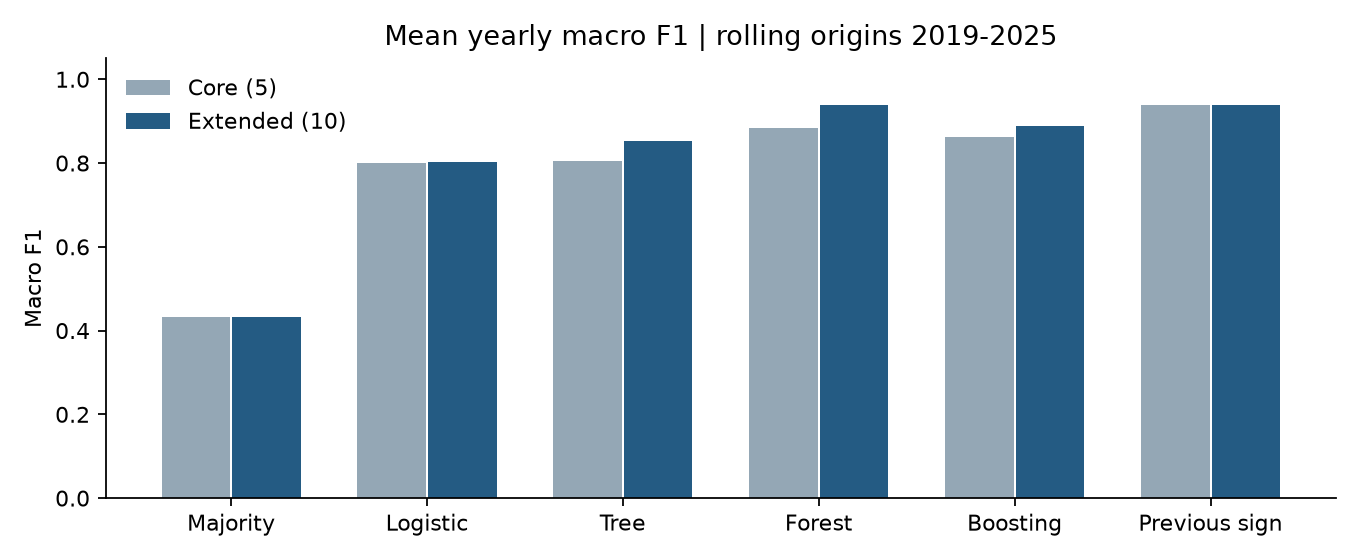

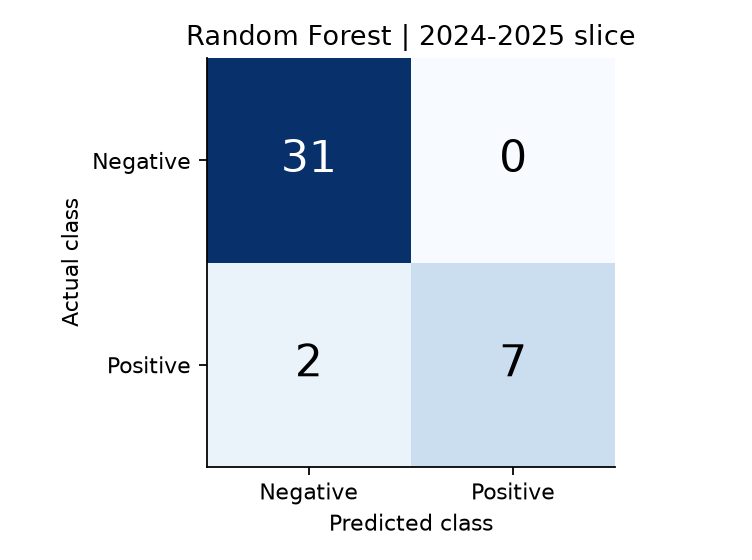

In [7]:
display(Image(filename="results/figures/model_comparison.png"))
display(Image(filename="results/figures/confusion_matrix.png"))

## 6. Which predictors did the model use?
Permutation importance measures the fall in the prediction score when an input is shuffled. SHAP allocates differences in model probability to inputs. Neither method proves why people move.

,kind,name,mean_drop_macro_f1,sd
10,group,Core socioeconomic,0.058,0.065
11,group,Education,0.244,0.121
12,group,Healthcare,0.003,0.048
13,group,Housing,0.004,0.018


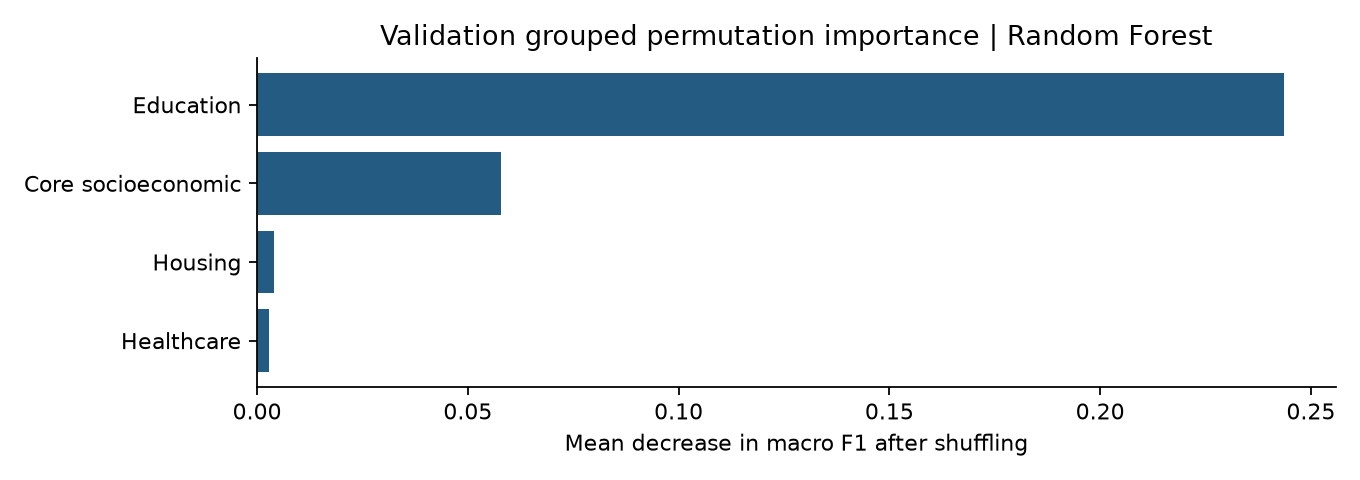

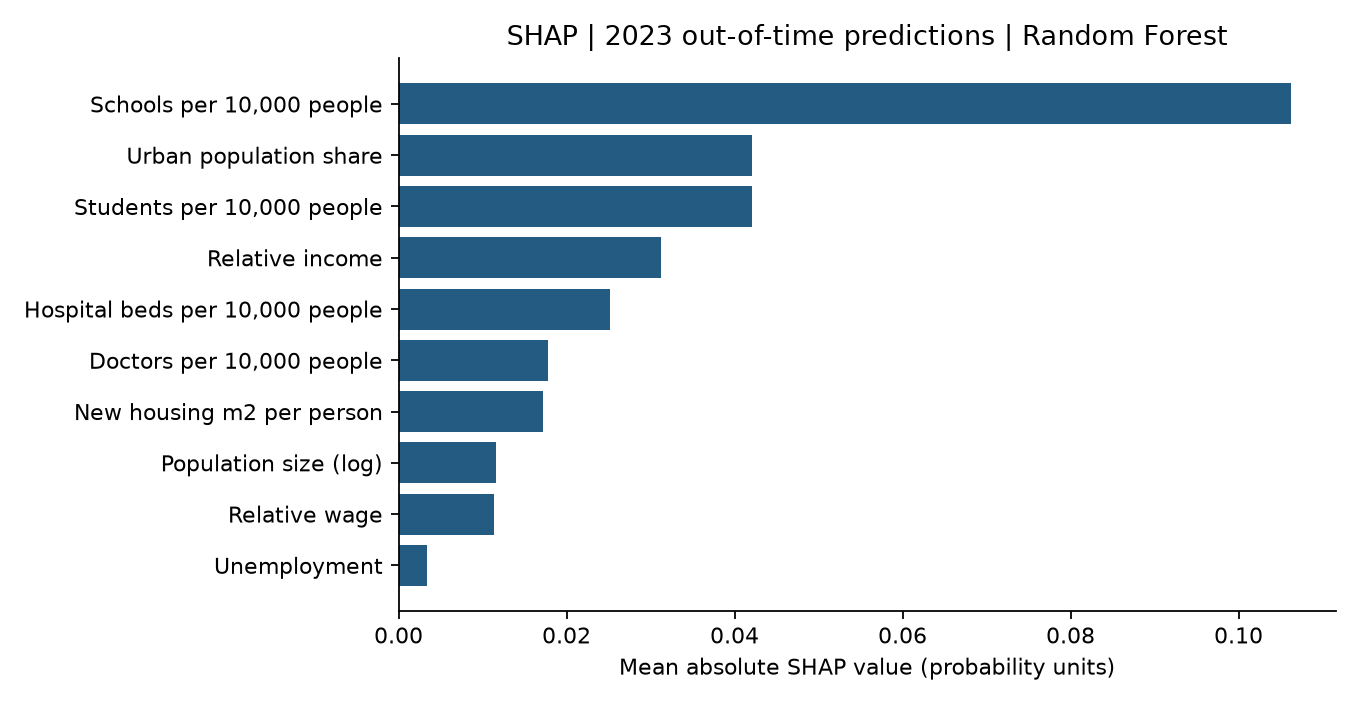

SHAP audit:
{
  "explainer": "shap.PermutationExplainer",
  "version": "0.54.1",
  "model": "Random Forest",
  "validation_year": 2023,
  "train_max_year": 2022,
  "background_n": 32,
  "explained_n": 20,
  "max_evals": 210,
  "seed": 42,
  "max_additivity_error": 4.440892098500626e-16,
  "units": "positive-class probability; descriptive, not causal"
}


In [8]:
display(pd.read_csv("results/permutation_importance.csv").query("kind == 'group'").round(3))
display(Image(filename="results/figures/group_importance.png"))
display(Image(filename="results/figures/shap_importance.png"))
print("SHAP audit:")
print(Path("results/shap_audit.json").read_text())

## 7. Check the data and saved results

In [9]:
for script in ["test_data.py", "test_analysis.py", "verify_results.py"]:
    result = subprocess.run([sys.executable, script], capture_output=True, text=True)
    print(script, "—", "PASS" if result.returncode == 0 else "FAIL")
    print(result.stderr[-600:])
    if script == "verify_results.py": print(result.stdout)
    result.check_returncode()

test_data.py — PASS
.....
----------------------------------------------------------------------
Ran 5 tests in 2.403s

OK



test_analysis.py — PASS
..
----------------------------------------------------------------------
Ran 2 tests in 0.005s

OK



verify_results.py — PASS

PASS: 84 yearly metric rows and 12 final-slice rows reproduced independently from 1392 predictions.
PASS: identical samples, labels, earlier-year training, and pre-2024 family selection.
PASS: SHAP values reconstruct saved probabilities; all 32 background rows precede 2023.
PASS: feature/group importance has 50 repetitions in every selection year.




## Main finding
Adding education, healthcare and housing improves the selected Random Forest on this historical comparison. In the 2024–2025 slice it gets 38 of 40 cases correct, matching the previous-year-sign reference. This is an exploratory extension with a small dependent regional sample. It does not establish a causal effect or independent confirmation on a new test set.